<a href="https://colab.research.google.com/github/shresta-28/TSA_DataScienceandAnalytics/blob/main/ev_strain_dataScience_TSA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction and Problem Statement

#### Overview
###### As EV adoption increases throughout Washington state neighborhoods, local power grids can face strain in peak charging times. This project analyzes electrical grid data to quantify electricity demand and stress caused by EV charging, and evaluate how much an overnight discount can decrease such stress.

In [79]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

ev_grid_og = pd.read_csv("ev_grid_dataset.csv")

# Data Processing and Cleaning

#### Handling Missing Data
###### To maintain dataset integrity, missing values were treated using median imputation.

#### Outlier Treatment
###### Outliers were found by checking what rows had a load column that was more than 120% of the median, or less than 50%. After tracking all anomalies to the "outlier_log.csv", they are replaced with the median of that column.

#### Recalculating Columns
###### To make sure totals align after data cleaning, derived metrics were recalculated. "EV_Charging_Load_MW" combined home and public EV charging load. "Total_Load_MW" combines base load and total EV charging load.

In [101]:
ev_grid_working = ev_grid_og.copy()

def count_blanks(data):
  print("Blanks in Avg_Temp_F:", data["Avg_Temp_F"].isna().sum())
  print("Blanks in Public_Charger_Count:", data["Public_Charger_Count"].isna().sum())

  load_cols = ["Base_Load_MW", "Home_EV_Load_MW", "Public_EV_Load_MW",
              "EV_Charging_Load_MW", "Total_Load_MW"]
  print("Blanks in load columns (should be 0):\n", data[load_cols].isna().sum())

  blanks_before = data.isna().sum()
  rows_before = len(data)
  print("All columns with blanks:\n", blanks_before[blanks_before > 0])
count_blanks(ev_grid_og)

Blanks in Avg_Temp_F: 54
Blanks in Public_Charger_Count: 54
Blanks in load columns (should be 0):
 Base_Load_MW           0
Home_EV_Load_MW        0
Public_EV_Load_MW      0
EV_Charging_Load_MW    0
Total_Load_MW          0
dtype: int64
All columns with blanks:
 Public_Charger_Count    54
Avg_Temp_F              54
dtype: int64


In [81]:
typical_temp = ev_grid_working.groupby(["Month", "Time_Block"])["Avg_Temp_F"].transform("median")
ev_grid_working["Avg_Temp_F"] = ev_grid_working["Avg_Temp_F"].fillna(typical_temp).round(1)

typical_chargers = ev_grid_working.groupby(["Zone_ID", "Year", "Month"])["Public_Charger_Count"].transform("median")
ev_grid_working["Public_Charger_Count"] = ev_grid_working["Public_Charger_Count"].fillna(typical_chargers).round()

count_blanks(ev_grid_working)


Blanks in Avg_Temp_F: 0
Blanks in Public_Charger_Count: 0
Blanks in load columns (should be 0):
 Base_Load_MW           0
Home_EV_Load_MW        0
Public_EV_Load_MW      0
EV_Charging_Load_MW    0
Total_Load_MW          0
dtype: int64
All columns with blanks:
 Series([], dtype: int64)


In [82]:
def find_outliers(check_cols, data):
  outliers={}
  for col in check_cols:
    ratio = data[col] / check_cols[col]
    outliers[col] = (ratio>1.2) | (ratio < 0.5)
    print(f"Total Outliers for {col} = {outliers[col].sum()}")
  return outliers

In [83]:
typical_base_load = ev_grid_working.groupby(["Zone_ID", "Month", "Time_Block"])["Base_Load_MW"].transform("median")
typical_home_load = ev_grid_working.groupby(["Zone_ID", "Year", "Time_Block", "Discount_Active"])["Home_EV_Load_MW"].transform("median")
typical_public_load = ev_grid_working.groupby(["Zone_ID", "Year", "Time_Block", "Discount_Active"])["Public_EV_Load_MW"].transform("median")

outlier_possible_cols = {"Base_Load_MW":typical_base_load, "Home_EV_Load_MW":typical_home_load, "Public_EV_Load_MW":typical_public_load}
outlier_rows = find_outliers(outlier_possible_cols, ev_grid_working)

log = []
for col in outlier_possible_cols:
    typicals = outlier_possible_cols[col]
    for i in ev_grid_working.index[outlier_rows[col]]:
        log.append({"Row_ID": ev_grid_working.at[i, "Row_ID"], "Column": col,
                    "Old_Value": ev_grid_working.at[i, col],
                    "New_Value": round(typicals[i], 3)})
    ev_grid_working.loc[outlier_rows[col], col] = typicals[outlier_rows[col]].round(3)

log_df = pd.DataFrame(log)
log_df.to_csv("outlier_log.csv", index=False)
print(len(log_df), "outliers fixed")

Total Outliers for Base_Load_MW = 46
Total Outliers for Home_EV_Load_MW = 82
Total Outliers for Public_EV_Load_MW = 97
225 outliers fixed


In [84]:
ev_grid_working["EV_Charging_Load_MW"] = (ev_grid_working["Home_EV_Load_MW"] + ev_grid_working["Public_EV_Load_MW"]).round(3)
ev_grid_working["Total_Load_MW"] = (ev_grid_working["Base_Load_MW"] + ev_grid_working["EV_Charging_Load_MW"]).round(3)
print(ev_grid_working)

      Row_ID Zone_ID      Zone_Name  Year  Month    Time_Block  Homes_in_Zone  \
0          1     Z01       Bellevue  2019      1       Morning           1500   
1          2     Z01       Bellevue  2019      1     Afternoon           1500   
2          3     Z01       Bellevue  2019      1  Evening_Peak           1500   
3          4     Z01       Bellevue  2019      1     Overnight           1500   
4          5     Z01       Bellevue  2019      2       Morning           1500   
...      ...     ...            ...   ...    ...           ...            ...   
5371    5372     Z16  Battle Ground  2025     11     Overnight            639   
5372    5373     Z16  Battle Ground  2025     12       Morning            639   
5373    5374     Z16  Battle Ground  2025     12     Afternoon            639   
5374    5375     Z16  Battle Ground  2025     12  Evening_Peak            639   
5375    5376     Z16  Battle Ground  2025     12     Overnight            639   

      EV_Share_Pct  Public_

## Exploratory Data Analysis

#### Extra Features
###### To prepare for data analysis, extra columns were made.
###### 1. "Date" with a DateTime format.
###### 2. "Home_EV_Cap_Pct" shows how much the Home EV charging takes up the grid load capacity
###### 3. "Stress_Per_EV" shows how much each EV adds up to the stress level that EV charging takes up
###### 4. "Policy_Status" reworks the Policy_Active column to be ready for use in data analysis
###### 5. "Total_Stress_Pct" shows how much the total load takes up of the avaiable total grid capacity.

#### Data Analysis and Graphs
###### - Line plots and heatmaps were used to confirm Evening Peak hours straining the electrical grid
###### - Linear regression maps were used to show how the weather and temperature impacts Base Laod
###### - Bar charts show how EV adoption percentages change across policy zones and how it affects stress

In [85]:
import matplotlib.patches as mpatches

ev_grid_working["Date"] = pd.to_datetime(
    ev_grid_working["Year"].astype(str) + "-" + ev_grid_working["Month"].astype(str).str.zfill(2) + "-01"
)

ev_grid_working["Home_EV_Cap_Pct"] = (ev_grid_working["Home_EV_Load_MW"] / ev_grid_working["Grid_Capacity_MW"]) * 100
ev_grid_working["Stress_Per_EV"] = ev_grid_working["Home_EV_Cap_Pct"]/ev_grid_working["EV_Share_Pct"]
ev_grid_working["Policy_Status"] = ev_grid_working["Discount_Active"].map(
    {"Yes": "Discount Active", "No": "No Discount"}
)

policy_zones = set(
    ev_grid_working[ev_grid_working["Discount_Active"] == "Yes"][
        "Zone_Name"
    ].unique()
)

ev_grid_working["Total_Stress_Pct"] = ( ev_grid_working["Total_Load_MW"] / ev_grid_working["Grid_Capacity_MW"] ) * 100

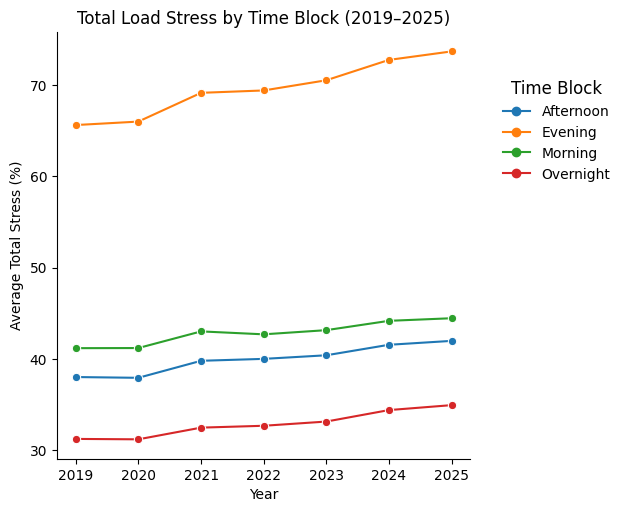

In [86]:
yearly_load = (
    ev_grid_working.set_index("Date")
    .groupby("Time_Block")["Total_Stress_Pct"]
    .resample("YS")
    .mean()
    .reset_index()
)

yearly_total_load_graph=sns.relplot(yearly_load, x="Date", y="Total_Stress_Pct", hue="Time_Block", kind="line", marker="o")
yearly_total_load_graph.set(title="Total Load Stress by Time Block (2019–2025)", ylabel="Average Total Stress (%)", xlabel="Year")
sns.move_legend(yearly_total_load_graph,  loc="upper right",
    title="Time Block",
    labels=["Afternoon", "Evening", "Morning", "Overnight"],
    bbox_to_anchor=(1, 0.9),
    fontsize=10,
    title_fontsize=12)

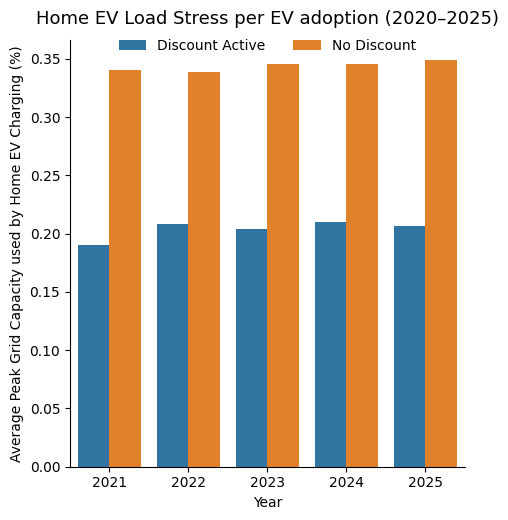

In [87]:
yearly_evening_byPolicy = (
    ev_grid_working[(ev_grid_working["Time_Block"] == "Evening_Peak") & (ev_grid_working["Year"] > 2020)]
    .groupby(["Year", "Policy_Status"])["Stress_Per_EV"]
    .mean()
    .reset_index()
)
yearly_evening_byPolicy_graph = sns.catplot(yearly_evening_byPolicy, x="Year", y="Stress_Per_EV", hue="Policy_Status", kind="bar")
yearly_evening_byPolicy_graph.set(xlabel = "Year", ylabel="Average Peak Grid Capacity used by Home EV Charging (%)")
yearly_evening_byPolicy_graph.fig.suptitle(
    "Home EV Load Stress per EV adoption (2020–2025)", y=1.03, x=0.45, fontsize=13
)
sns.move_legend(yearly_evening_byPolicy_graph,  loc="lower center",
    title=None,
    bbox_to_anchor=(0.45, 0.92),
    ncol=2,
    fontsize=10,
    title_fontsize=12)

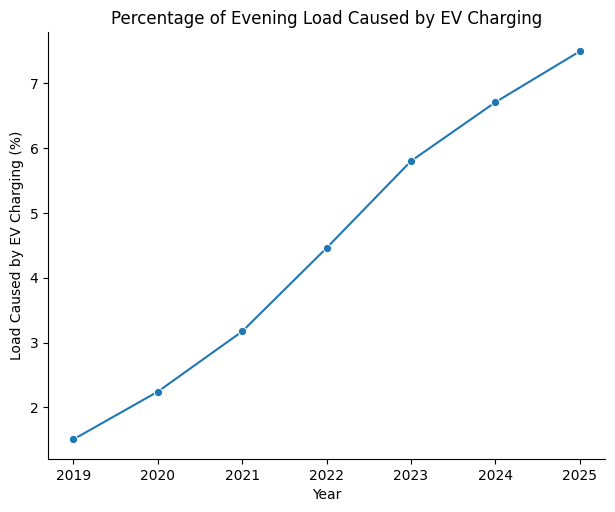

In [88]:
evening_load = ev_grid_working[
    ev_grid_working["Time_Block"] == "Evening_Peak"
].copy()

evening_load["EV_Caused_Load_Pct"] = (evening_load["EV_Charging_Load_MW"] / evening_load["Total_Load_MW"]) * 100
evening_load_mean = evening_load.groupby("Year")["EV_Caused_Load_Pct"].mean()
ev_caused_load_graph = sns.relplot(pd.DataFrame(evening_load_mean), y="EV_Caused_Load_Pct", x="Year", kind="line", marker="o", aspect=10/8)
ev_caused_load_graph.set(title="Percentage of Evening Load Caused by EV Charging", xlabel="Year", ylabel="Load Caused by EV Charging (%)")

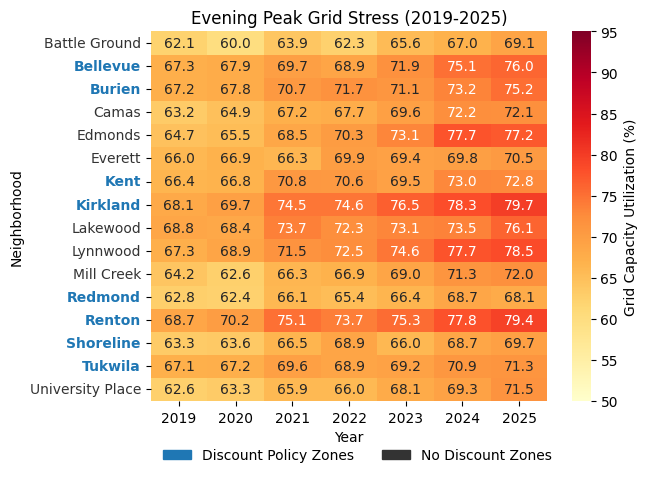

In [89]:
total_stress_table = ev_grid_working[ev_grid_working["Time_Block"]=="Evening_Peak"].pivot_table(
  index="Zone_Name", columns="Year", values="Total_Stress_Pct", aggfunc="mean"
)

total_stress_graph = sns.heatmap(
  total_stress_table,
  annot=True,
  fmt=".1f",
  cmap="YlOrRd",
  vmin=50,
  vmax=95,
  cbar_kws={"label": "Grid Capacity Utilization (%)"},
)

total_stress_graph.set(title="Evening Peak Grid Stress (2019-2025)", xlabel="Year", ylabel="Neighborhood")

for tick_label in total_stress_graph.get_yticklabels():
  zone_name = tick_label.get_text()
  if zone_name in policy_zones:
    tick_label.set_color("#1f77b4")
    tick_label.set_fontweight("bold")
  else:
    tick_label.set_color("#333333")

policy_patch = mpatches.Patch(
  color="#1f77b4", label="Discount Policy Zones"
)

control_patch = mpatches.Patch(
  color="#333333", label="No Discount Zones"
)

total_stress_graph.legend(
  handles=[policy_patch, control_patch],
  loc="lower left",
  bbox_to_anchor=(0, -0.2),
  ncol=2,
  frameon=False,
)

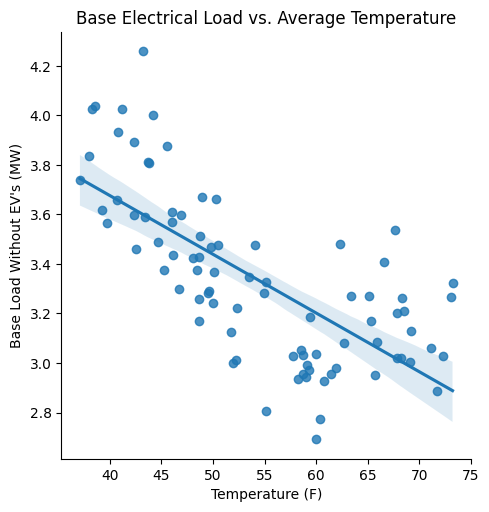

In [90]:
base_load_weather_graph = sns.lmplot(ev_grid_working[(ev_grid_working["Zone_Name"] == "Bellevue") & (ev_grid_working["Time_Block"]=="Evening_Peak")], x="Avg_Temp_F", y="Base_Load_MW")
base_load_weather_graph.set(title="Base Electrical Load vs. Average Temperature", xlabel="Temperature (F)", ylabel="Base Load Without EV's (MW)")

## Machine Learning and Counterfactual Simulations

#### Predictive Modeling
###### A RandomForestRegressor was used to model and predict total grid stress based on neighborhood and policy characteristics.
###### -  Features: Home counts, EV counts, Charger counts, Temperature, Grid Capacity, Policy, and Time Block.
###### - The model was evaluated by testing the previously split testing data and getting the root mean squared error (RMSE) of 3.176% and R^2 value of 0.953

In [91]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np

ev_grid_working["Policy_Numeric"] = ev_grid_working["Discount_Active"].map({"Yes": 1, "No": 0})
ev_grid_working["Time_Block_Numeric"] = ev_grid_working["Time_Block"].map({"Morning": 1, "Afternoon": 2, "Evening_Peak": 3, "Overnight": 4})
features = [
    "Homes_in_Zone",
    "EV_Share_Pct",
    "Public_Charger_Count",
    "Avg_Temp_F",
    "Grid_Capacity_MW",
    "Policy_Numeric",
    "Time_Block_Numeric"
]
target = "Total_Stress_Pct"

X = ev_grid_working[features]
Y = ev_grid_working[target]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

discount_simulation_model = RandomForestRegressor(n_estimators=100, random_state=42)
discount_simulation_model.fit(X_train, Y_train)
y_pred = discount_simulation_model.predict(X_test)

print(f"Model R² Score: {r2_score(Y_test, y_pred):.3f}")
print(
    f"Model Root Mean Squared Error (RMSE):"
    f" {np.sqrt(mean_squared_error(Y_test, y_pred)):.3f}%"
)

Model R² Score: 0.953
Model Root Mean Squared Error (RMSE): 3.176%


--------Mill Creek Impact--------
Estimated Grid Stress without discount:  40.43% of capacity
Estimated Grid Stress with discount:  40.94% of capacity
Estimated Grid Stress Reduction with Policy: -0.51% of capacity
--------Lynnwood Impact--------
Estimated Grid Stress without discount:  42.31% of capacity
Estimated Grid Stress with discount:  42.51% of capacity
Estimated Grid Stress Reduction with Policy: -0.20% of capacity
--------Edmonds Impact--------
Estimated Grid Stress without discount:  43.81% of capacity
Estimated Grid Stress with discount:  43.73% of capacity
Estimated Grid Stress Reduction with Policy:  0.08% of capacity
--------Everett Impact--------
Estimated Grid Stress without discount:  41.97% of capacity
Estimated Grid Stress with discount:  42.35% of capacity
Estimated Grid Stress Reduction with Policy: -0.39% of capacity
--------Lakewood Impact--------
Estimated Grid Stress without discount:  41.25% of capacity
Estimated Grid Stress with discount:  41.49% of capacity

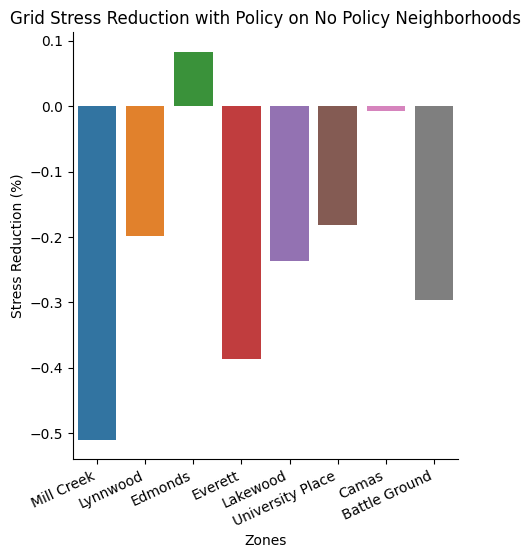

In [92]:
def predict_policy_impact(neighborhood_name):
  latest_data = ev_grid_working[ev_grid_working["Zone_Name"] == neighborhood_name].iloc[-1].copy()
  future_ev_share = min(50.0, latest_data["EV_Share_Pct"] * 1.5)
  time_blocks = {
      1: "Morning",
      2: "Afternoon",
      3: "Evening_Peak",
      4: "Overnight",
  }
  for tb_num, tb_name in time_blocks.items():
    scenario_no_policy = pd.DataFrame([{
        "Homes_in_Zone": latest_data["Homes_in_Zone"] * 1.05,
        "EV_Share_Pct": future_ev_share,
        "Public_Charger_Count": latest_data["Public_Charger_Count"] + 5,
        "Avg_Temp_F": latest_data["Avg_Temp_F"],
        "Grid_Capacity_MW": latest_data["Grid_Capacity_MW"],
        "Policy_Numeric": 0,
        "Time_Block_Numeric": tb_num
    }])

  scenario_with_policy = scenario_no_policy.copy()
  scenario_with_policy["Policy_Numeric"] = 1

  stress_no_policy = discount_simulation_model.predict(scenario_no_policy)[0]
  stress_with_policy = discount_simulation_model.predict(scenario_with_policy)[0]
  stress_reduction = stress_no_policy - stress_with_policy

  print(f"Estimated Grid Stress without discount: {stress_no_policy: 0.2f}% of capacity")
  print(f"Estimated Grid Stress with discount: {stress_with_policy: 0.2f}% of capacity")
  print(f"Estimated Grid Stress Reduction with Policy: {stress_reduction: 0.2f}% of capacity")
  return stress_reduction

discount_simulations = []
no_policy = ev_grid_working[~ev_grid_working["Zone_Name"].isin(policy_zones)]["Zone_Name"].unique()
for zone in no_policy:
    print(f"--------{zone} Impact--------")
    discount_simulations.append({"Zone_Name": zone, "Stress_Reduction": predict_policy_impact(zone)})
discount_simulations_dataframe = pd.DataFrame(discount_simulations)
stress_reduction_with_policy_fake_graph = sns.catplot(discount_simulations_dataframe, kind="bar", y="Stress_Reduction", x="Zone_Name", hue="Zone_Name")
stress_reduction_with_policy_fake_graph.set(title="Grid Stress Reduction with Policy on No Policy Neighborhoods", xlabel="Zones", ylabel="Stress Reduction (%)")
stress_reduction_with_policy_fake_graph.set_xticklabels(rotation=25, horizontalalignment="right")

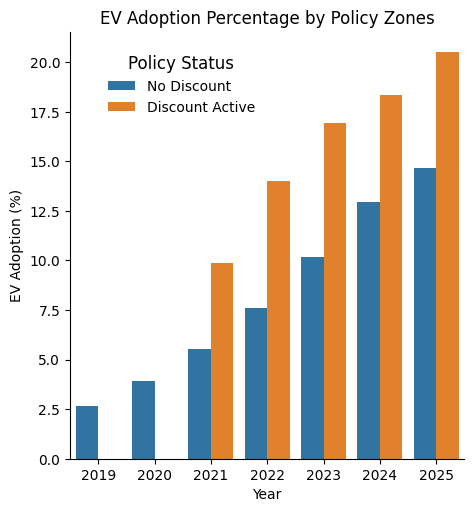

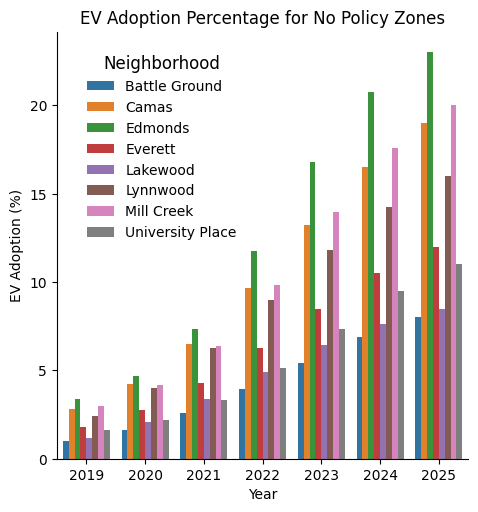

In [93]:
ev_adoption_rates = ev_grid_working.groupby(["Policy_Status", "Year"])["EV_Share_Pct"].mean().reset_index()
ev_adoption_rates_graph = sns.catplot(ev_adoption_rates, x="Year", y="EV_Share_Pct", hue="Policy_Status", kind="bar")
ev_adoption_rates_graph.set(title="EV Adoption Percentage by Policy Zones", xlabel="Year", ylabel="EV Adoption (%)")
sns.move_legend(ev_adoption_rates_graph,  loc="upper right",
    title="Policy Status",
    bbox_to_anchor=(0.45, 0.95),
    fontsize=10,
    title_fontsize=12)

ev_adoption_rates_no_discount = ev_grid_working[~ev_grid_working["Zone_Name"].isin(policy_zones)].groupby(["Zone_Name", "Year"])["EV_Share_Pct"].mean().reset_index()
ev_adoption_rates_no_discount_graph = sns.catplot(ev_adoption_rates_no_discount, x="Year", y="EV_Share_Pct", hue="Zone_Name", kind="bar")
ev_adoption_rates_no_discount_graph.set(title="EV Adoption Percentage for No Policy Zones", xlabel="Year", ylabel="EV Adoption (%)")
sns.move_legend(ev_adoption_rates_no_discount_graph,  loc="upper left",
    title="Neighborhood",
    bbox_to_anchor=(0.15, 0.95),
    fontsize=10,
    title_fontsize=12)

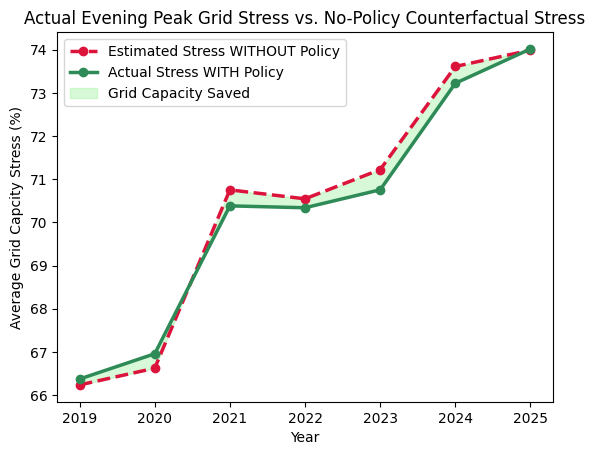

In [100]:
policy_evenings = ev_grid_working[
    (ev_grid_working["Zone_Name"].isin(policy_zones))
    & (ev_grid_working["Time_Block"] == "Evening_Peak")
].copy()
grid_alternate_no_policy = policy_evenings.copy()
grid_alternate_no_policy["Policy_Numeric"]=0

features = [
    "Homes_in_Zone",
    "EV_Share_Pct",
    "Public_Charger_Count",
    "Avg_Temp_F",
    "Grid_Capacity_MW",
    "Policy_Numeric",
    "Time_Block_Numeric",
]

policy_evenings["Counterfactual_No_Policy_Stress"] = (discount_simulation_model.predict(grid_alternate_no_policy[features]))
yearly_savings = (
    policy_evenings.groupby("Year")[[
        "Total_Stress_Pct",
        "Counterfactual_No_Policy_Stress",
    ]]
    .mean()
    .reset_index()
)

plt.plot(
    yearly_savings["Year"],
    yearly_savings["Counterfactual_No_Policy_Stress"],
    label="Estimated Stress WITHOUT Policy",
    color="crimson",
    linestyle="--",
    marker="o",
    linewidth=2.5,
)
plt.plot(
    yearly_savings["Year"],
    yearly_savings["Total_Stress_Pct"],
    label="Actual Stress WITH Policy",
    color="seagreen",
    marker="o",
    linewidth=2.5,
)

plt.fill_between(
    yearly_savings["Year"],
    yearly_savings["Total_Stress_Pct"],
    yearly_savings["Counterfactual_No_Policy_Stress"],
    color="lightgreen",
    alpha=0.35,
    label="Grid Capacity Saved",
)

plt.gca().set(
    title = "Actual Evening Peak Grid Stress vs. No-Policy Counterfactual Stress",
    xlabel = "Year", ylabel="Average Grid Capcity Stress (%)"
)
plt.legend()